In [7]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import (apply_plot_style, 
                         get_layers, 
                         load_ii_curves, 
                         linestyle_for_language, 
                         _min_token_length)
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()

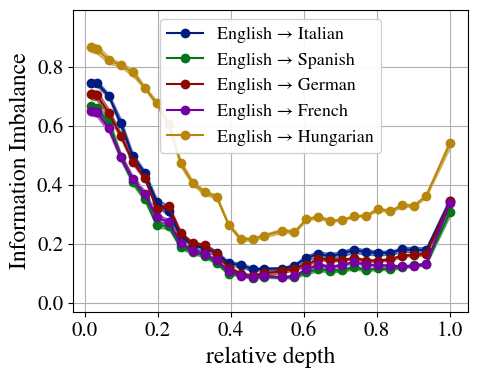

In [8]:
model = 'deepseek'
_model ='deepseek'

# model = "llama"
# _model = 'llama8b'

# MODEL_PRETTY = {"deepseek": "DeepSeek-V3", "llama": "Llama3-8b"}
# _model = MODEL_PRETTY.get(model, model)

mask = 2
n_files = 500
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0


aux_A = "source"
aux_B = "target"
k_II = 10
avg_tokens = 1
n_tokens = 20
Nbits = 0
seeds = list(range(5))
language_pairs = [
    ("english", "italian"),
    ("english", "spanish"),
    ("german", "english"),
    ("english", "french"),
    ("english", "hungarian"),
]

layers = get_layers(_model, depths)
x = layers / depths[_model]

FIGSIZE = (5,4)
LABEL_FONTSIZE = 17
TICK_FONTSIZE = 15
LEGEND_FONTSIZE = 13

fig, ax = plt.subplots(1, 1, figsize=FIGSIZE)

markers = ["o", "s", "^", "D", "v", "P", "X", "*", "+", "x"]

for i, (languageA, languageB) in enumerate(language_pairs):
    mean_ii, std_ii = load_ii_curves(
        base="../results/santiago/",
        batch_shuffle=batch_shuffle,
        model=model,
        aux_A=aux_A,
        aux_B=aux_B,
        n_files=n_files,
        min_token_length=_min_token_length(model, languageA, languageB),
        languageA=languageA,
        languageB=languageB,
        mask=mask,
        k=k_II,
        Nbits=Nbits,
        seeds=seeds,
        n_tokens=n_tokens,
        avg_tokens=avg_tokens,
    )

    color = colors[i % len(colors)]
    linestyle_AB = ':' if languageB == "english" else '-'
    linestyle_BA = ':' if languageA == "english" else '-'
    marker_AB = 's' if languageB == "english" else 'o'
    marker_BA = 's' if languageA == "english" else 'o'

    # AB
    if languageA == 'english':
      ax.plot(
          x,
          mean_ii[0],
          label=f"{languageA.capitalize()} → {languageB.capitalize()}",
          linestyle=linestyle_AB,
          marker=marker_AB,
          color=color,
      )
      ax.fill_between(x, mean_ii[0] - std_ii[0], mean_ii[0] + std_ii[0], color=color, alpha=0.5)

    # BA
    else:
      ax.plot(
          x,
          mean_ii[1],
          label=f"{languageB.capitalize()} → {languageA.capitalize()}",
          linestyle=linestyle_BA,
          marker=marker_BA,
          color=color,
      )
      ax.fill_between(x, mean_ii[1] - std_ii[1], mean_ii[1] + std_ii[1], color=color, alpha=0.5)

ax.set_xlabel("relative depth", fontsize=LABEL_FONTSIZE)
ax.set_ylabel("Information Imbalance", fontsize=LABEL_FONTSIZE)
ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
ax.grid()

# Legend inside plot
handles, labels = ax.get_legend_handles_labels()
english_to_other = [(h, l) for h, l in zip(handles, labels) if l.startswith("English →")]
other_to_english = [(h, l) for h, l in zip(handles, labels) if l.endswith("→ English")]
remaining = [
    (h, l)
    for h, l in zip(handles, labels)
    if not l.startswith("English →") and not l.endswith("→ English")
]
ordered = english_to_other + other_to_english + remaining
ordered_handles = [h for h, _ in ordered]
ordered_labels = [l for _, l in ordered]

ymin, ymax = ax.get_ylim()
pad = 0.08 * (ymax - ymin)
ax.set_ylim(ymin - pad, ymax + pad)

ax.legend(ordered_handles, ordered_labels, loc="upper center", fontsize=LEGEND_FONTSIZE, framealpha=0.9)
# box = ax.get_position()
# ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
# ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))



fig.savefig(f'../results/figs/english-pivot.pdf',bbox_inches='tight')
plt.show()

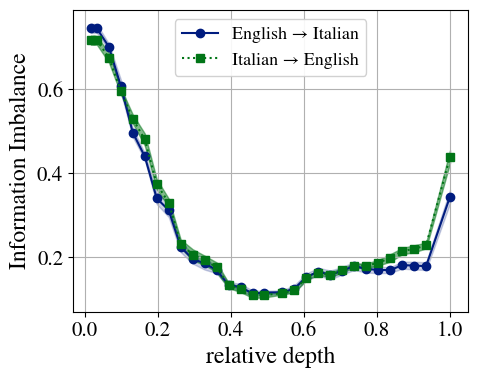

In [9]:
# Single-language plot with variable-based labels and colors
languageA, languageB = "english", "italian"

# Reuse Fig. 1 palette: same pair color, different line styles/markers.
pair_index = next(
    (
        i
        for i, (la, lb) in enumerate(language_pairs)
        if (la, lb) == (languageA, languageB) or (la, lb) == (languageB, languageA)
    ),
    0,
)
pair_color = colors[pair_index % len(colors)]
forward_color = pair_color  # English -> target
reciprocal_color = colors[1 % len(colors)]  # target -> English

label_forward = f"{languageA.capitalize()} → {languageB.capitalize()}"
label_reciprocal = f"{languageB.capitalize()} → {languageA.capitalize()}"
out_path = f"../results/figs/english-pivot-{languageB}-only.pdf"

mean_ii, std_ii = load_ii_curves(
    base="../results/santiago/",
    batch_shuffle=batch_shuffle,
    model=model,
    aux_A=aux_A,
    aux_B=aux_B,
    n_files=n_files,
    min_token_length=_min_token_length(model, languageA, languageB),
    languageA=languageA,
    languageB=languageB,
    mask=mask,
    k=k_II,
    Nbits=Nbits,
    seeds=seeds,
    n_tokens=n_tokens,
    avg_tokens=avg_tokens,
)

layers = get_layers(_model, depths)
x = layers / depths[_model]

fig, ax = plt.subplots(1, 1, figsize=(5,4))

ax.plot(
    x,
    mean_ii[0],
    label=label_forward,
    linestyle="-",
    marker="o",
    color=forward_color,
)
ax.fill_between(x, mean_ii[0] - std_ii[0], mean_ii[0] + std_ii[0], color=forward_color, alpha=0.2)

ax.plot(
    x,
    mean_ii[1],
    label=label_reciprocal,
    linestyle='dotted',
    marker="s",
    color=reciprocal_color,
)
ax.fill_between(x, mean_ii[1] - std_ii[1], mean_ii[1] + std_ii[1], color=reciprocal_color, alpha=0.5)

ax.set_xlabel("relative depth", fontsize=LABEL_FONTSIZE)
ax.set_ylabel("Information Imbalance", fontsize=LABEL_FONTSIZE)
ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)
ax.grid()
ax.legend(loc="upper center", fontsize=LEGEND_FONTSIZE, framealpha=0.9)

fig.savefig(out_path, bbox_inches="tight")
plt.show()
